# Exception Handling

An **exception** is an error that Python raises while a program runs: a missing file, a division by zero, a network timeout. If nothing handles it, the program stops. **Exception handling** lets the program react: retry, use a default value, or report a clear message.

**After this lesson you can:**

1. Use `try`, `except`, `else` and `finally`.
2. Raise exceptions and define your own exception classes.
3. Chain exceptions and handle several errors with `ExceptionGroup`.
4. Implement a retry with exponential backoff.

## 1. `try` / `except` / `else` / `finally`

```python
try:
    ...                 # code that can fail
except ValueError as err:
    ...                 # runs if this kind of error happens
else:
    ...                 # runs only if no error happened
finally:
    ...                 # always runs: clean-up
```

Catch **specific** exceptions. A bare `except:` also catches `KeyboardInterrupt` and hides bugs.

In [1]:
def parse_price(text: str) -> float:
    try:
        value = float(text.replace(",", "."))
    except ValueError:
        print(f"  cannot parse {text!r}; using 0.0")
        return 0.0
    else:
        return value
    finally:
        print(f"  parsed {text!r}")

for t in ["12.5", "7,99", "free"]:
    print("result:", parse_price(t))

  parsed '12.5'
result: 12.5
  parsed '7,99'
result: 7.99
  cannot parse 'free'; using 0.0
  parsed 'free'
result: 0.0


## 2. The Exception Hierarchy

All built-in exceptions are classes. `except LookupError` catches both `KeyError` and `IndexError`, because they are subclasses of `LookupError`.

| Exception | Typical cause |
| :--- | :--- |
| `ValueError` | correct type, wrong value: `int("abc")` |
| `TypeError` | wrong type: `"a" + 1` |
| `KeyError` / `IndexError` | missing key / index out of range |
| `FileNotFoundError` | missing file (subclass of `OSError`) |
| `ZeroDivisionError` | division by zero |
| `TimeoutError` | an operation took too long |

In [2]:
tests = [lambda: int("abc"), lambda: "a" + 1, lambda: {"a": 1}["b"], lambda: [1, 2][5],
         lambda: open("missing_file.txt"), lambda: 1 / 0]
for fn in tests:
    try:
        fn()
    except Exception as err:
        parents = [c.__name__ for c in type(err).__mro__[1:-2]]
        print(f"{type(err).__name__:<18} parents: {parents} | {err}")

ValueError         parents: ['Exception'] | invalid literal for int() with base 10: 'abc'
TypeError          parents: ['Exception'] | can only concatenate str (not "int") to str
KeyError           parents: ['LookupError', 'Exception'] | 'b'
IndexError         parents: ['LookupError', 'Exception'] | list index out of range
FileNotFoundError  parents: ['OSError', 'Exception'] | [Errno 2] No such file or directory: 'missing_file.txt'
ZeroDivisionError  parents: ['ArithmeticError', 'Exception'] | division by zero


## 3. Raise Your Own Exceptions

Use `raise` when your function receives input that it cannot handle. A custom exception class gives callers a precise type to catch. `raise ... from err` keeps the original cause (**exception chaining**), which makes debugging easier.

In [3]:
class InsufficientStockError(Exception):
    """Raised when an order asks for more items than the warehouse has."""

    def __init__(self, item: str, requested: int, available: int):
        super().__init__(f"{item}: requested {requested}, available {available}")
        self.item, self.requested, self.available = item, requested, available

STOCK = {"laptop": 3, "mouse": 40}

def reserve(item: str, qty: int) -> None:
    if qty <= 0:
        raise ValueError(f"quantity must be positive, got {qty}")
    try:
        available = STOCK[item]
    except KeyError as err:
        raise LookupError(f"unknown item {item!r}") from err
    if qty > available:
        raise InsufficientStockError(item, qty, available)
    STOCK[item] -= qty

for args in [("mouse", 5), ("laptop", 10), ("tablet", 1), ("mouse", 0)]:
    try:
        reserve(*args)
        print("reserved", args)
    except InsufficientStockError as err:
        print("stock error:", err, "| missing", err.requested - err.available)
    except (LookupError, ValueError) as err:
        print(f"{type(err).__name__}: {err} | cause: {err.__cause__!r}")

reserved ('mouse', 5)
stock error: laptop: requested 10, available 3 | missing 7
LookupError: unknown item 'tablet' | cause: KeyError('tablet')
ValueError: quantity must be positive, got 0 | cause: None


## 4. Several Errors at Once: `ExceptionGroup`

Python 3.11 added `ExceptionGroup` and the `except*` syntax. They report several independent failures together, for example the validation errors of one form, or tasks that run in parallel (M02, asyncio).

In [4]:
def validate(record: dict) -> None:
    errors = []
    if not record.get("email", "").count("@") == 1:
        errors.append(ValueError("invalid email"))
    if not isinstance(record.get("age"), int):
        errors.append(TypeError("age must be an integer"))
    if errors:
        raise ExceptionGroup("record is invalid", errors)

try:
    validate({"email": "ali.example.com", "age": "29"})
except* ValueError as group:
    print("value problems:", [str(e) for e in group.exceptions])
except* TypeError as group:
    print("type problems :", [str(e) for e in group.exceptions])

value problems: ['invalid email']
type problems : ['age must be an integer']


## 5. Retry with Exponential Backoff

Network calls fail now and then for temporary reasons. A common pattern is to **retry** with a growing wait: 0.1 s, 0.2 s, 0.4 s, ... (**exponential backoff**), plus a small random **jitter** so that many clients do not retry at the same moment. After a maximum number of attempts, the function raises the error.

The flaky service below is a simulation: each call fails with probability 0.4.

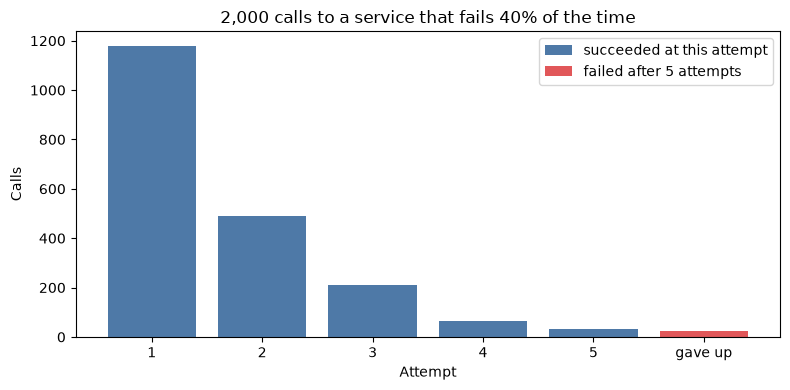

success rate without retry : 59.0%
success rate with 5 retries: 98.9% (theory: 1 - 0.4^5 = 99.0%)


In [5]:
import random
import time

import matplotlib.pyplot as plt

class TemporaryError(Exception):
    pass

def flaky_service(rng) -> str:
    if rng.random() < 0.4:
        raise TemporaryError("service unavailable")
    return "ok"

def call_with_retry(fn, rng, max_attempts=5, base_delay=0.001):
    for attempt in range(1, max_attempts + 1):
        try:
            return fn(rng), attempt
        except TemporaryError:
            if attempt == max_attempts:
                raise
            time.sleep(base_delay * 2 ** (attempt - 1) * (1 + rng.random() * 0.1))

rng = random.Random(42)
attempts, failures = [], 0
for _ in range(2000):
    try:
        _, n = call_with_retry(flaky_service, rng)
        attempts.append(n)
    except TemporaryError:
        failures += 1

fig, ax = plt.subplots(figsize=(8, 4))
counts = [attempts.count(k) for k in range(1, 6)]
ax.bar(range(1, 6), counts, color="#4E79A7", label="succeeded at this attempt")
ax.bar(6, failures, color="#E15759", label="failed after 5 attempts")
ax.set_xticks(range(1, 7), ["1", "2", "3", "4", "5", "gave up"])
ax.set(title="2,000 calls to a service that fails 40% of the time", xlabel="Attempt", ylabel="Calls")
ax.legend()
plt.tight_layout()
plt.show()

print(f"success rate without retry : {counts[0] / 2000:.1%}")
print(f"success rate with 5 retries: {len(attempts) / 2000:.1%} (theory: 1 - 0.4^5 = {1 - 0.4**5:.1%})")

Without retries, about 60% of the calls succeed. With up to five attempts, more than 98% succeed: the measured value agrees with the theory $1 - 0.4^5$.

*Insight: Handle an exception only where you can do something useful: retry, use a default, or add context and re-raise. Never write `except Exception: pass`; it hides the bug and you lose the error message.*

## Real-World Use Case or Analogy

Exception handling is like the **safety procedures of an airline**. The crew does not stop every flight because of a small problem. For each known situation there is a procedure: a delayed passenger, a closed runway, a technical fault. Some problems are handled on board (`except`); serious ones go to the ground team with a clear report (`raise ... from err`); the checklist after landing always happens (`finally`).

Production systems retry calls to databases, payment providers and LLM APIs with exponential backoff. Libraries such as `tenacity` and the retry settings of HTTP clients implement exactly the pattern in Section 5.